# Name : Manthan Madankar
# Class : C2-B2
# Roll no : 16
# ML Practical 7

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.naive_bayes import GaussianNB

from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

pd.set_option('display.max_columns', None)

In [ ]:
df=pd.read_csv("Raisin_Dataset.xlsx - Raisin_Grains_Dataset.csv")

In [ ]:
df.head()

,Area,MajorAxisLength,MinorAxisLength,Eccentricity,ConvexArea,Extent,Perimeter,Class
0,87524,442.246011,253.291155,0.819738,90546,0.758651,1184.040,Kecimen
1,75166,406.690687,243.032436,0.801805,78789,0.684130,1121.786,Kecimen
2,90856,442.267048,266.328318,0.798354,93717,0.637613,1208.575,Kecimen
3,45928,286.540559,208.760042,0.684989,47336,0.699599,844.162,Kecimen
4,79408,352.190770,290.827533,0.564011,81463,0.792772,1073.251,Kecimen


In [ ]:
df.tail()

,Area,MajorAxisLength,MinorAxisLength,Eccentricity,ConvexArea,Extent,Perimeter,Class
895,83248,430.077308,247.838695,0.817263,85839,0.668793,1129.072,Besni
896,87350,440.735698,259.293149,0.808629,90899,0.636476,1214.252,Besni
897,99657,431.706981,298.837323,0.721684,106264,0.741099,1292.828,Besni
898,93523,476.344094,254.176054,0.845739,97653,0.658798,1258.548,Besni
899,85609,512.081774,215.271976,0.907345,89197,0.632020,1272.862,Besni


In [ ]:
df.isnull().sum()

,0
Area,0
MajorAxisLength,0
MinorAxisLength,0
Eccentricity,0
ConvexArea,0
Extent,0
Perimeter,0
Class,0


In [ ]:
df.duplicated().sum()

np.int64(0)

In [ ]:
df["Class"].unique()

array(['Kecimen', 'Besni'], dtype=object)

In [ ]:
df["Class"].unique()

array(['Kecimen', 'Besni'], dtype=object)

In [ ]:
df["Class"].value_counts()

,count
Class,
Kecimen,450
Besni,450


## Bar-Plot

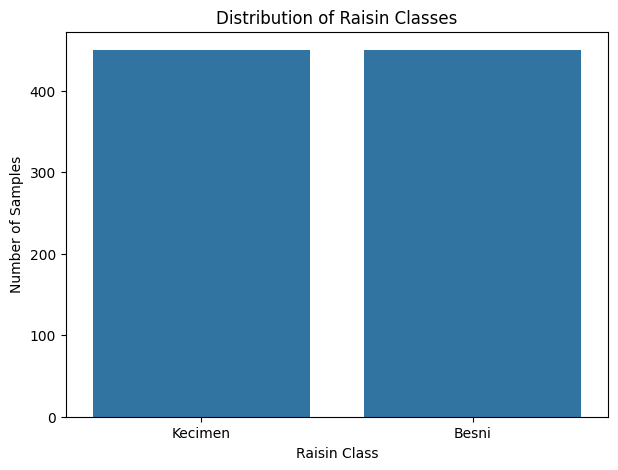

In [ ]:
plt.figure(figsize=(7,5))

sns.countplot(data = df, x = "Class")

plt.title("Distribution of Raisin Classes")
plt.xlabel("Raisin Class")
plt.ylabel("Number of Samples")

plt.show()

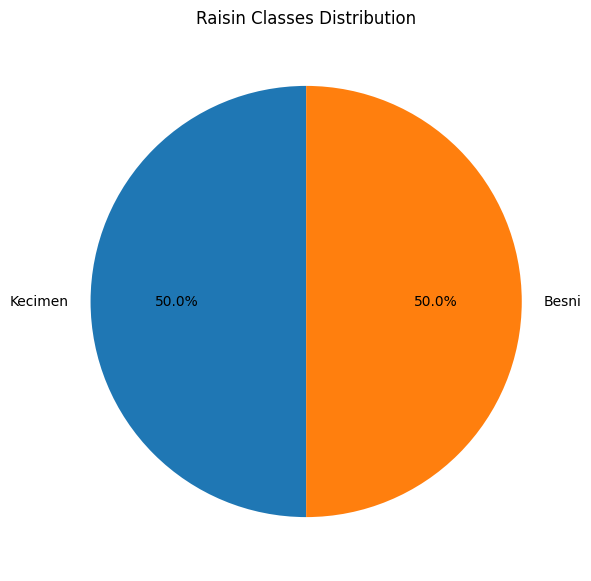

In [ ]:
class_counts = df["Class"].value_counts()

plt.figure(figsize=(7, 7))

plt.pie(class_counts, labels=class_counts.index, autopct='%1.1f%%', startangle=90)
plt.title("Raisin Classes Distribution")

plt.show()

In [ ]:
numerical_features = df.select_dtypes(include = np.number).columns

print("Numerical Features:")
print(numerical_features)

Numerical Features:
Index(['Area', 'MajorAxisLength', 'MinorAxisLength', 'Eccentricity',
       'ConvexArea', 'Extent', 'Perimeter'],
      dtype='object')


## Histograms

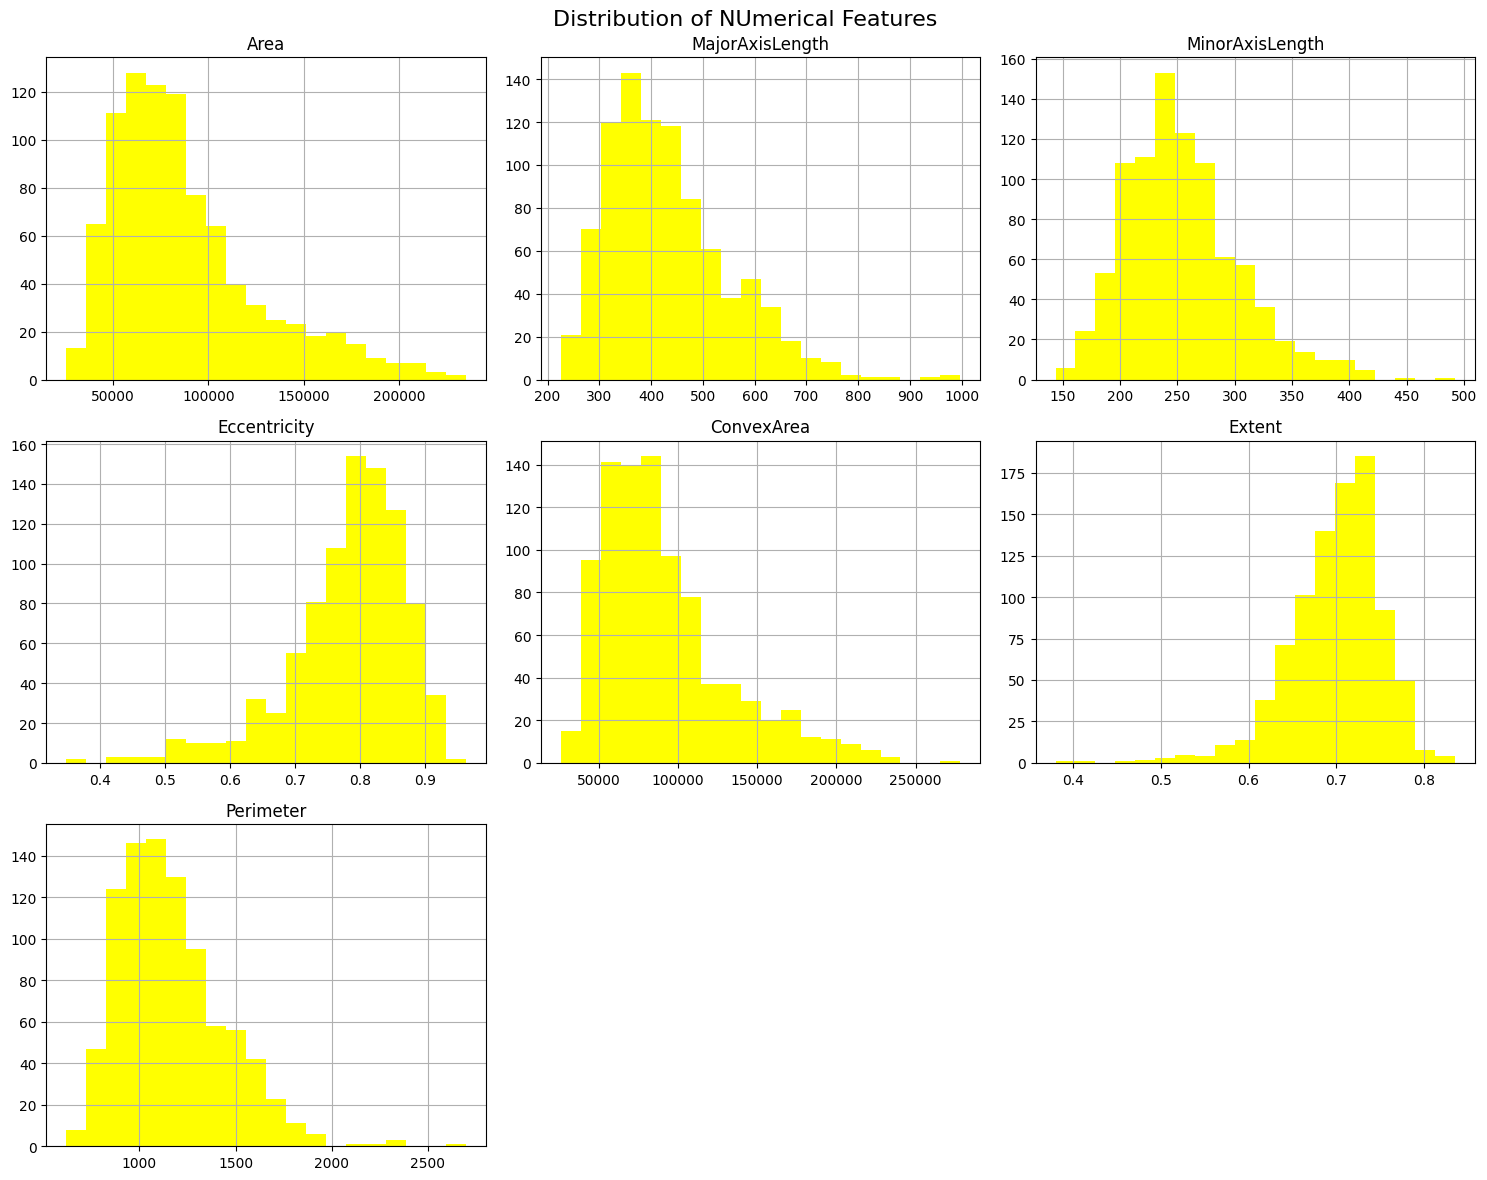

In [ ]:
df[numerical_features].hist(figsize=(15, 12), bins=20, color='yellow')
plt.suptitle("Distribution of NUmerical Features",fontsize = 16,)

plt.tight_layout()
plt.show()

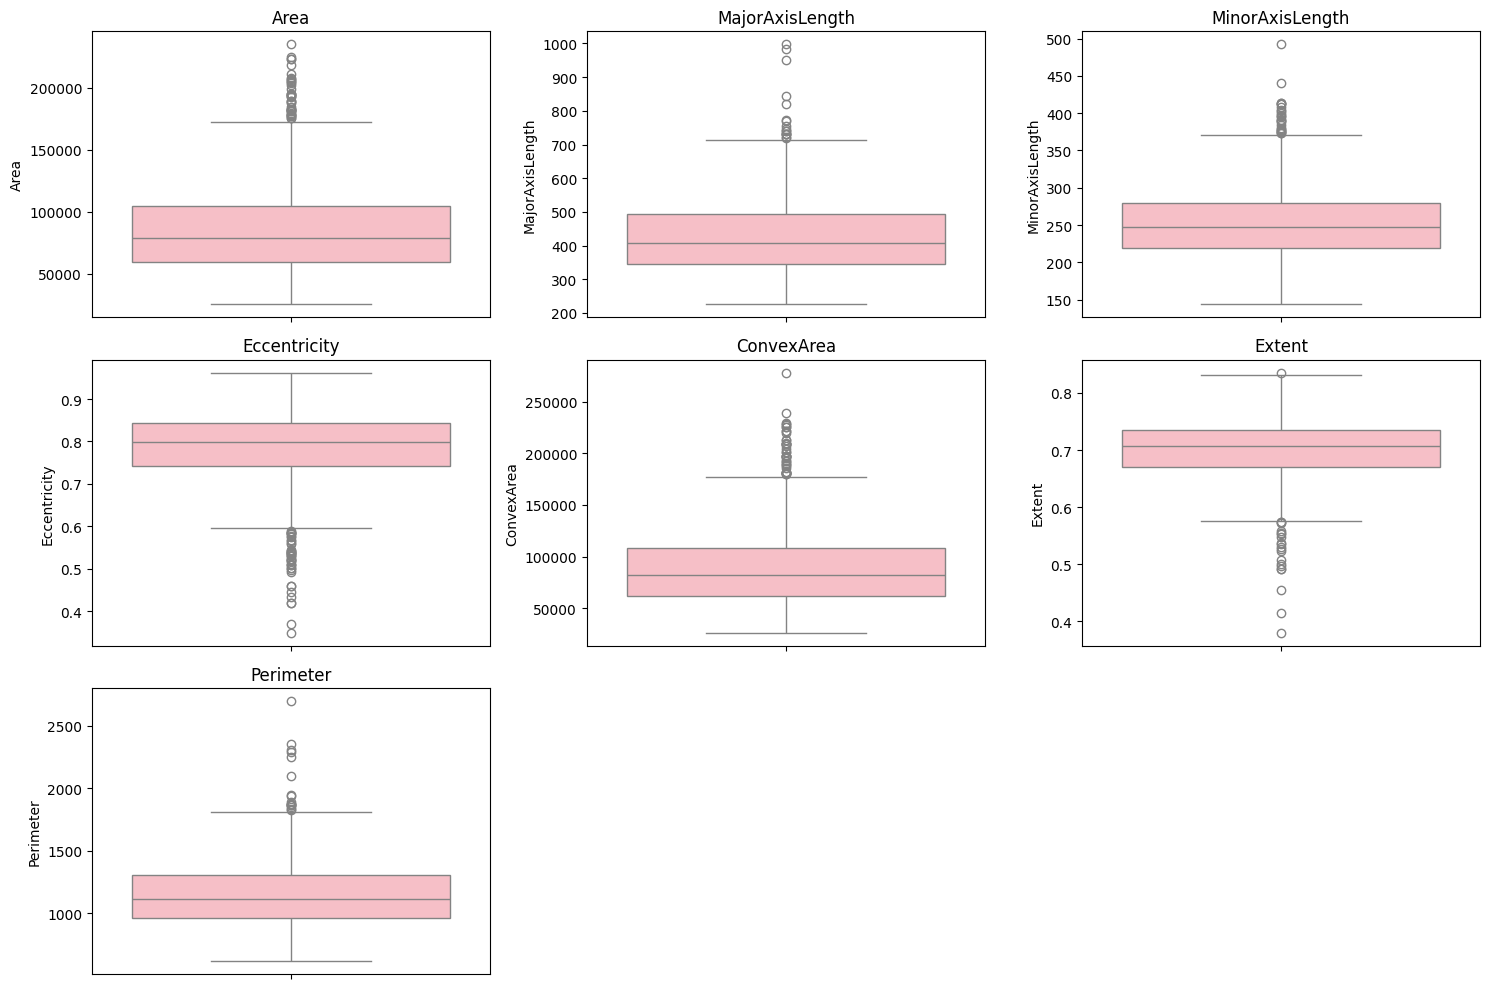

In [ ]:
plt.figure(figsize=(15, 10))

for i, col in enumerate(numerical_features, 1):
    plt.subplot(3, 3, i)
    sns.boxplot(y=df[col], color='lightpink')
    plt.title(col)

plt.tight_layout()
plt.show()

## Histograms with kde functions

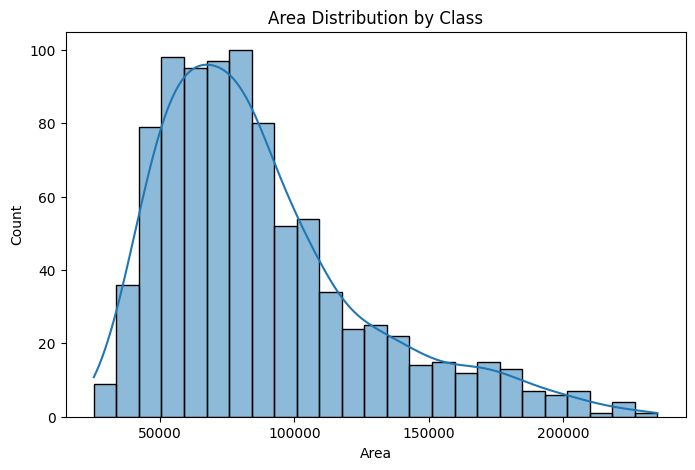

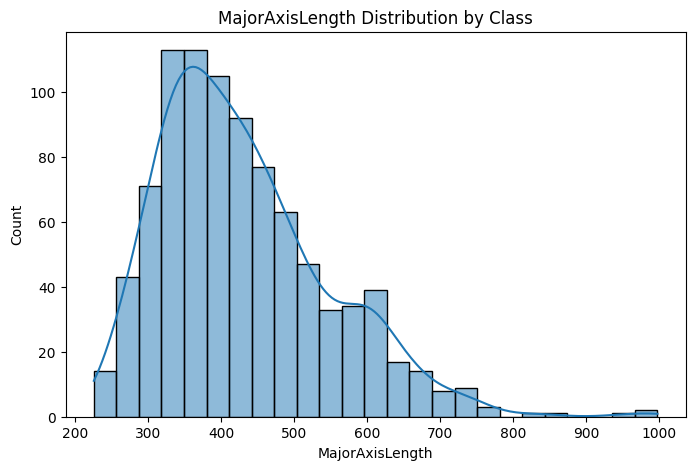

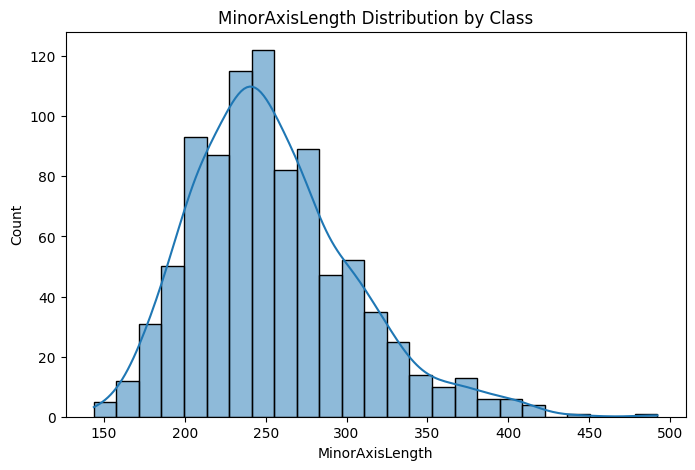

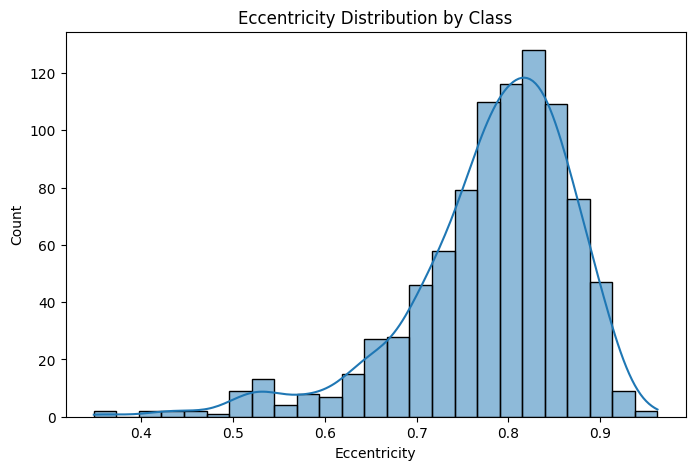

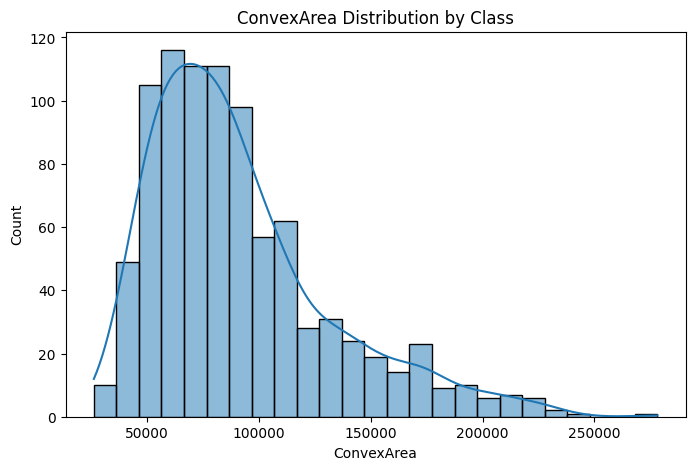

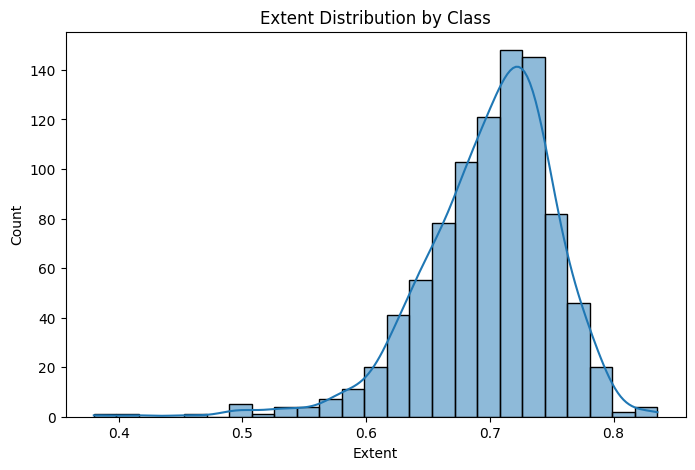

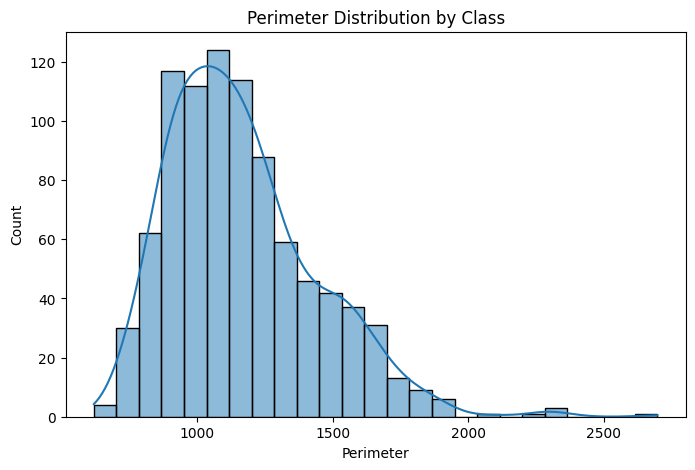

In [ ]:
for columns in numerical_features:

  plt.figure(figsize=(8, 5))

  sns.histplot(data = df, x = columns, kde = True, bins = 25)

  plt.title(f"{columns} Distribution by Class")

  plt.show()

## Correlation Matrix

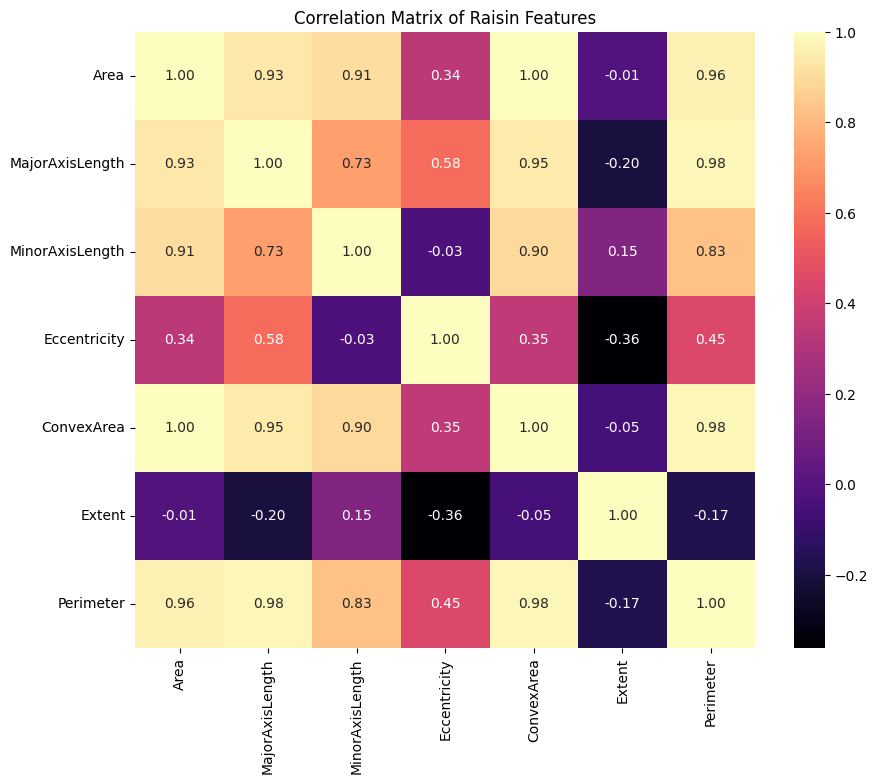

In [ ]:
correlation_matrix = df[numerical_features].corr()

plt.figure(figsize=(10, 8))
sns.heatmap(correlation_matrix, annot=True, cmap='magma', fmt=".2f")
plt.title("Correlation Matrix of Raisin Features")
plt.show()

# Scatterplot

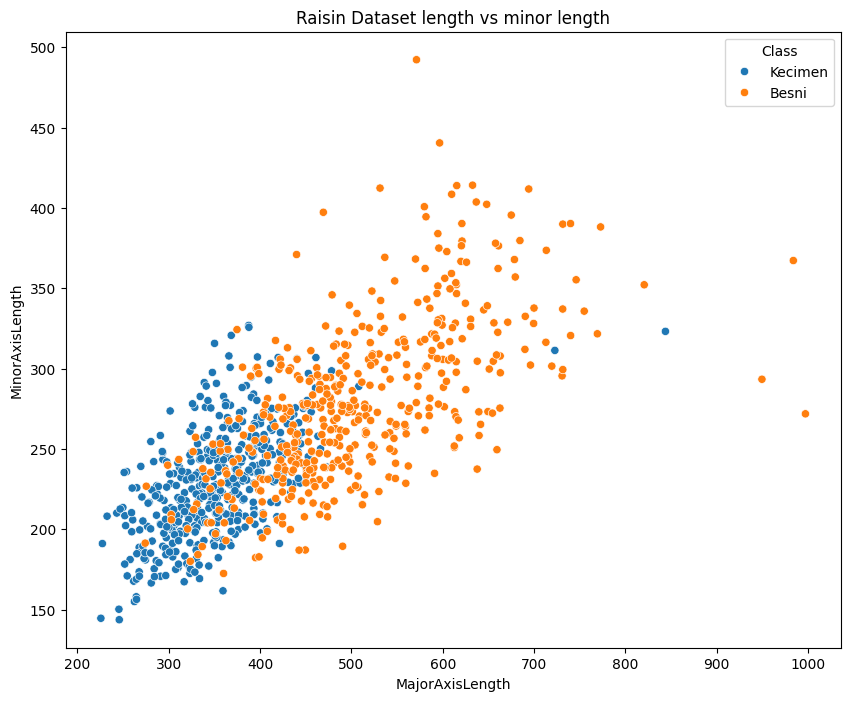

In [ ]:
plt.figure(figsize=(10, 8))
sns.scatterplot(data=df,x='MajorAxisLength',y='MinorAxisLength',hue='Class')
plt.title('Raisin Dataset length vs minor length')
plt.show()

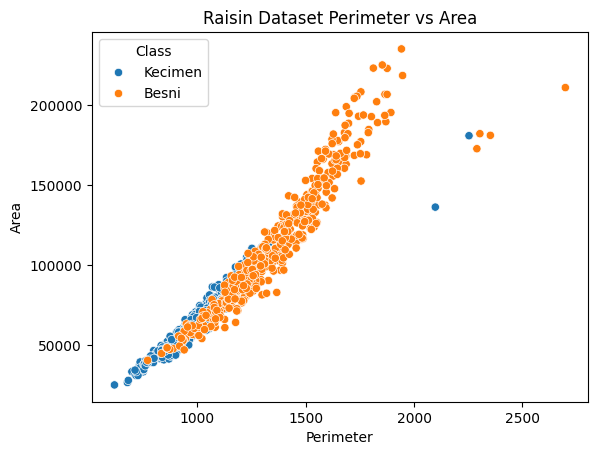

In [ ]:
sns.scatterplot(data=df,x='Perimeter',y='Area',hue='Class')
plt.title('Raisin Dataset Perimeter vs Area')
plt.show()

In [ ]:
label_encoder=LabelEncoder()
df['Class_encoded']=label_encoder.fit_transform(df['Class'])
print(df[['Class','Class_encoded']].head())

     Class  Class_encoded
0  Kecimen              1
1  Kecimen              1
2  Kecimen              1
3  Kecimen              1
4  Kecimen              1


In [ ]:
print('class mapping')
for i,j in enumerate(label_encoder.classes_):
    print(i,"=",j)

class mapping
0 = Besni
1 = Kecimen


In [ ]:
x=df[numerical_features]
y=df['Class_encoded']
print('x shape=',x.shape)
print('y shape=',y.shape)

x shape= (900, 7)
y shape= (900,)


In [ ]:
X_train,X_test,y_train,y_test=train_test_split(x,y,test_size=0.2,random_state=42,stratify=y)

In [ ]:
print('Training sample=',X_train.shape[0])
print('Testing sample=',X_test.shape[0])

Training sample= 720
Testing sample= 180


In [ ]:
GaussianNB()

GaussianNB()

In [ ]:
gnb=GaussianNB()
gnb.fit(X_train,y_train)

GaussianNB()

In [ ]:
y_pred=gnb.predict(X_test)
print('predicted labels:')
print(y_pred)

predicted labels:
[1 0 0 1 0 1 0 1 1 1 1 1 1 1 0 1 1 1 0 0 0 1 1 1 1 1 1 1 1 1 1 1 0 0 1 0 1
 0 0 0 0 0 0 0 0 0 0 1 0 0 1 1 0 1 1 1 0 1 0 0 0 1 1 0 0 1 0 1 1 1 1 0 0 1
 1 1 0 1 0 1 0 1 1 1 1 0 1 1 1 1 0 1 1 0 1 1 1 1 1 0 1 1 1 0 1 0 1 0 1 1 0
 1 1 0 1 1 1 0 0 1 0 1 0 1 1 1 0 0 1 1 1 1 0 1 1 1 1 1 0 1 1 1 0 1 1 0 0 1
 1 1 1 0 0 1 1 1 0 1 1 0 1 1 0 0 0 1 1 1 1 1 1 0 1 1 1 0 0 1 0 1]


In [ ]:
comparison=pd.DataFrame({'Actual':y_test.values,'Predicted':y_pred})
print(comparison.head())

   Actual  Predicted
0       0          1
1       0          0
2       0          0
3       1          1
4       0          0


In [ ]:
comparison['Actual_Class']=label_encoder.inverse_transform(comparison['Actual'])
comparison['Predicted_Class']=label_encoder.inverse_transform(comparison['Predicted'])
print(comparison.head())

   Actual  Predicted Actual_Class Predicted_Class
0       0          1        Besni         Kecimen
1       0          0        Besni           Besni
2       0          0        Besni           Besni
3       1          1      Kecimen         Kecimen
4       0          0        Besni           Besni


In [ ]:
accuracy=accuracy_score(y_test,y_pred)
print('Accuracy:',accuracy)
print('Accuracy (%)',accuracy*100)

Accuracy: 0.8166666666666667
Accuracy (%) 81.66666666666667


In [ ]:
precision=precision_score(y_test,y_pred)
print('Precision:',precision)

Precision: 0.7522123893805309


In [ ]:
recall=recall_score(y_test,y_pred)
print('Recall:',recall)

Recall: 0.9444444444444444


In [ ]:
f1=f1_score(y_test,y_pred)
print('F1 Score:',f1)

F1 Score: 0.8374384236453202


In [ ]:
print(f'Accuracy: {accuracy:.4f}')
print(f'Precision: {precision:.4f}')
print(f'Recall: {recall:.4f}')
print(f'F1 Score: {f1:.4f}')

Accuracy: 0.8167
Precision: 0.7522
Recall: 0.9444
F1 Score: 0.8374


In [ ]:
print('Classification report')
print(classification_report(y_test,y_pred,target_names=label_encoder.classes_))

Classification report
              precision    recall  f1-score   support

       Besni       0.93      0.69      0.79        90
     Kecimen       0.75      0.94      0.84        90

    accuracy                           0.82       180
   macro avg       0.84      0.82      0.81       180
weighted avg       0.84      0.82      0.81       180



In [ ]:
cm=confusion_matrix(y_test,y_pred)
print('Confusion Matrix:')
print(cm)

Confusion Matrix:
[[62 28]
 [ 5 85]]


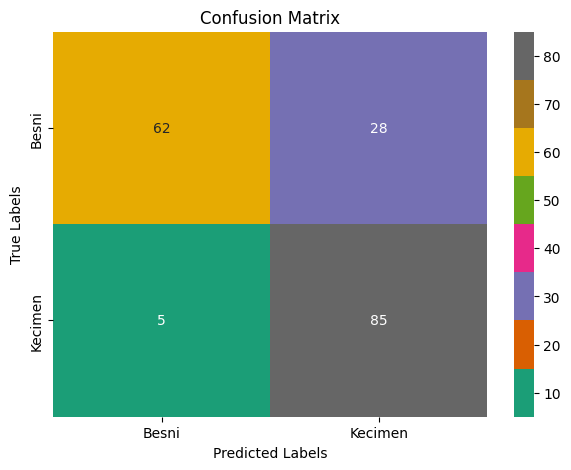

In [ ]:
plt.figure(figsize=(7,5))
sns.heatmap(cm,annot=True,fmt='d',cmap='Dark2',xticklabels=label_encoder.classes_,yticklabels=label_encoder.classes_)
plt.title('Confusion Matrix')
plt.xlabel('Predicted Labels')
plt.ylabel('True Labels')
plt.show()

In [ ]:
from sklearn.metrics import accuracy_score
y_train_pred=gnb.predict(X_train)
y_test_pred=gnb.predict(X_test)
train_accuracy=accuracy_score(y_train,y_train_pred)
test_accuracy=accuracy_score(y_test,y_test_pred)
print('Training Accuracy:',train_accuracy)
print('Testing Accuracy:',test_accuracy)

Training Accuracy: 0.8263888888888888
Testing Accuracy: 0.8166666666666667


# Main Hyperparameters

In [ ]:
GaussianNB(var_smoothing=1e-9)

GaussianNB()

In [ ]:
print(gnb.get_params())

{'priors': None, 'var_smoothing': 1e-09}


In [ ]:
smoothing_values=[1e-12,1e-10,1e-9,1e-8,1e-7,1e-6,1e-5,1e-4,1e-3,1e-2]
results=[]
for v in smoothing_values:
    model=GaussianNB(var_smoothing=v)
    model.fit(X_train,y_train)
    prediction=model.predict(X_test)
    acc=accuracy_score(y_test,prediction)
    prec=precision_score(y_test,prediction)
    rec=recall_score(y_test,prediction)
    f1=f1_score(y_test,prediction)
    results.append([v,acc,prec,rec,f1])

In [ ]:
results_df=pd.DataFrame(results,columns=['var_smoothing','accuracy','precision','recall','f1'])
results_df

,var_smoothing,accuracy,precision,recall,f1
0,1.000000e-12,0.833333,0.767857,0.955556,0.851485
1,1.000000e-10,0.816667,0.752212,0.944444,0.837438
2,1.000000e-09,0.816667,0.752212,0.944444,0.837438
3,1.000000e-08,0.816667,0.752212,0.944444,0.837438
4,1.000000e-07,0.811111,0.745614,0.944444,0.833333
5,1.000000e-06,0.811111,0.745614,0.944444,0.833333
6,1.000000e-05,0.811111,0.741379,0.955556,0.834951
7,1.000000e-04,0.788889,0.720339,0.944444,0.817308
8,1.000000e-03,0.788889,0.720339,0.944444,0.817308
9,1.000000e-02,0.783333,0.714286,0.944444,0.813397


In [ ]:
area=float(input("Enter Area:"))
major_axis=float(input("Enter Major Axis Length:"))
minor_axis=float(input("Enter Minor Axis Length:"))
eccentricity=float(input("Enter Eccentricity:"))
convex_area=float(input("Enter convex area:"))
extent=float(input("Enter Extent:"))
perimeter=float(input("Enter perimeter:"))
new_sample=pd.DataFrame({'Area':[area],'MajorAxisLength':[major_axis],'MinorAxisLength':[minor_axis],'Eccentricity':[eccentricity],'ConvexArea':[convex_area],'Extent':[extent],'Perimeter':[perimeter]})
prediction=gnb.predict(new_sample)
predicted_class=label_encoder.inverse_transform(prediction)
print('\nPredicted Raisin class:',predicted_class[0])

Enter Area:75166
Enter Major Axis Length:406
Enter Minor Axis Length:24
Enter Eccentricity:0.80
Enter convex area:78789
Enter Extent:0.6
Enter perimeter:1121.7

Predicted Raisin class: Besni
